# Setup

In [1]:
lapply(c('viridis', 'ggthemes', 'skimr'),
       function(pkg_name) { if(! pkg_name %in% installed.packages()) { install.packages(pkg_name)} } )

library(viridis)    # A nice color scheme for plots.
library(ggthemes)   # Common themes to change the look and feel of plots.
library(scales)     # Graphical scales map data to aesthetics in plots.
library(skimr)      # Better summaries of data.
library(lubridate)  # Date library from the tidyverse.
library(tidyverse)  # Data wrangling packages.
library(bigrquery)  # Data extraction from Google BigQuery
library(data.table )

# Load required libraries
library(dplyr)
library(tidyr)
library(purrr)
library(broom)

install.packages("pROC")
library(pROC)

install.packages("pheatmap")
library(pheatmap)


## Plot setup.
theme_set(theme_bw(base_size = 14)) # Default theme for plots.

#' Returns a data frame with a y position and a label, for use annotating ggplot boxplots.
#'
#' @param d A data frame.
#' @return A data frame with column y as max and column label as length.
get_boxplot_fun_data <- function(df) {
  return(data.frame(y = max(df), label = stringr::str_c('N = ', length(df))))
}

# Get the bucket name
my_bucket <- Sys.getenv('WORKSPACE_BUCKET')

[[1]]
NULL

[[2]]
NULL

[[3]]
NULL

Loading required package: viridisLite


Attaching package: ‘scales’


The following object is masked from ‘package:viridis’:

    viridis_pal



Attaching package: ‘lubridate’


The following objects are masked from ‘package:base’:

    date, intersect, setdiff, union


── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr   1.1.4     ✔ readr   2.1.5
✔ forcats 1.0.0     ✔ stringr 1.5.1
✔ ggplot2 3.5.2     ✔ tibble  3.2.1
✔ purrr   1.0.4     ✔ tidyr   1.3.1
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ readr::col_factor() masks scales::col_factor()
✖ purrr::discard()    masks scales::discard()
✖ dplyr::filter()     masks stats::filter()
✖ dplyr::lag()        masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors

Attaching package: ‘data.table’


The following objects are masked from ‘package:dplyr’:

    between, first, last


The following object is

## Load and merge data

In [2]:
#Load demographic data
name_of_file_in_bucket <- 'Demographic_and_ancestry_covariates.csv'
system(paste0("gsutil cp ", my_bucket, "/data/", name_of_file_in_bucket, " ."), intern=T)
demo  <- read_csv(name_of_file_in_bucket) |> 
    select(-c(income, education)) |> 
    rename(age = age_at_last_event)

#Load SES data
name_of_file_in_bucket <- 'SES_data.csv'
system(paste0("gsutil cp ", my_bucket, "/data/", name_of_file_in_bucket, " ."), intern=T)
sdoh_data  <- read_csv(name_of_file_in_bucket)

#MERGE
demo_sdoh<-merge(demo, sdoh_data, on="person_id", how="inner")

#Load PRS data
name_of_file_in_bucket <- 'adjusted_PRS_scores.csv'
system(paste0("gsutil cp ", my_bucket, "/data/", name_of_file_in_bucket, " ."), intern=T)
PRS  <- read_csv(name_of_file_in_bucket) 

#MERGE
all_data_0<-merge(demo_sdoh, PRS, on="person_id", how="inner")

#Load Case control info 
name_of_file_in_bucket <- 'Case_Control_df.csv'
system(paste0("gsutil cp gs://fc-secure-672eeb92-4859-4ed9-9f59-d4349f3534a0/notebooks/Case_Control_df.csv ."), intern=T)
case_control  <- read_csv(name_of_file_in_bucket)

#MERGE
merged_data<-merge(all_data_0, case_control, on="person_id", how="left")

#Load PsRS data 
name_of_file_in_bucket <- 'individual_PsRS.csv'
system(paste0("gsutil cp ", my_bucket, "/data/", name_of_file_in_bucket, " ."), intern=T)
PsRS <- read_csv(name_of_file_in_bucket)

#MERGE
merged_data<-merge(merged_data, PsRS, on="person_id", how="left")
colnames(merged_data)

character(0)

Rows: 135557 Columns: 51
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr   (9): SexGender, ancestry_pred, education, where_born, military, health...
dbl  (30): person_id, race_unknown, age_today, PC_1, PC_2, PC_3, PC_4, PC_5,...
lgl   (8): AIAN, Asian, Black, Mid, Multiple, PI, White, His
dttm  (1): basics_survey_datetime
date  (3): date_of_birth, min_date, max_date

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


character(0)

Rows: 214915 Columns: 13
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
dbl (13): person_id, income, education, per_poverty_threshold, lower_poverty...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


character(0)

...

character(0)

Rows: 265954 Columns: 10
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
dbl (10): person_id, Asthma, Afib, BreastC, CKD, CHD, HyperC, ProstateC, t2d...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


character(0)

Rows: 104908 Columns: 9
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
dbl (9): person_id, Afib_PsRS, Asthma_PsRS, BreastC_PsRS, CHD_PsRS, CKD_PsRS...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


[1] "person_id"                         "date_of_birth"                    
 [3] "AIAN"                              "Asian"                            
 [5] "Black"                             "Mid"                              
 [7] "Multiple"                          "PI"                               
 [9] "White"                             "His"                              
[11] "race_unknown"                      "SexGender"                        
[13] "age_today"                         "ancestry_pred"                    
[15] "PC_1"                              "PC_2"                             
[17] "PC_3"                              "PC_4"                             
[19] "PC_5"                              "PC_6"                             
[21] "PC_7"                              "PC_8"                             
[23] "PC_9"                              "PC_10"                            
[25] "PC_11"                             "PC_12"                            
[27] "PC_13"                             "PC_14"                            
[29] "PC_15"                             "PC_16"                            
[31] "number_living"                     "where_born"                       
[33] "military"                          "healthcare"                       
[35] "disabled"                          "sexual_orientation"               
[37] "LGBTQIA"                           "basics_survey_datetime"           
[39] "income_grouped"                    "min_date"                         
[41] "max_date"                          "ehr_length"                       
[43] "relative_health"                   "record_depth"                     
[45] "visit_frequency"                   "age"                              
[47] "record_depth_winsorized"           "visit_frequency_winsorized"       
[49] "age2"                              "income"                           
[51] "education"                         "per_poverty_threshold"            
[53] "lower_poverty"                     "american_community_survey_year"   
[55] "fraction_assisted_income"          "fraction_no_high_school_education"
[57] "lower_median_income"               "fraction_no_health_insurance"     
[59] "fraction_poverty"                  "fraction_vacant_housing"          
[61] "deprivation_index"                 "Asthma_adjusted_score"            
[63] "Afib_adjusted_score"               "BreastC_adjusted_score"           
[65] "CKD_adjusted_score"                "CHD_adjusted_score"               
[67] "ProstateC_adjusted_score"          "t1d_adjusted_score"               
[69] "t2d_adjusted_score"                "Asthma"                           
[71] "Afib"                              "BreastC"                          
[73] "CKD"                               "CHD"                              
[75] "HyperC"                            "ProstateC"                        
[77] "t2d"                               "t1d"                              
[79] "Afib_PsRS"                         "Asthma_PsRS"                      
[81] "BreastC_PsRS"                      "CHD_PsRS"                         
[83] "CKD_PsRS"                          "ProstateC_PsRS"                   
[85] "t1d_PsRS"                          "t2d_PsRS"

In [3]:
str(merged_data)

merged_data <- merged_data %>%
  mutate(
    SexGenderCis_male = ifelse(SexGender == "Cis_male", 1, 0),
    SexGenderCis_female = ifelse(SexGender == "Cis_female", 1, 0),
    SexGenderSGM = ifelse(SexGender == "SGM", 1, 0)
  )

'data.frame':	104508 obs. of  86 variables:
 $ person_id                        : num  1e+06 1e+06 1e+06 1e+06 1e+06 ...
 $ date_of_birth                    : Date, format: "1940-06-15" "1966-06-15" ...
 $ AIAN                             : logi  FALSE FALSE FALSE FALSE FALSE FALSE ...
 $ Asian                            : logi  FALSE FALSE FALSE FALSE FALSE FALSE ...
 $ Black                            : logi  FALSE TRUE FALSE FALSE TRUE FALSE ...
 $ Mid                              : logi  FALSE FALSE FALSE FALSE FALSE FALSE ...
 $ Multiple                         : logi  FALSE FALSE FALSE FALSE FALSE FALSE ...
 $ PI                               : logi  FALSE FALSE FALSE FALSE FALSE FALSE ...
 $ White                            : logi  TRUE FALSE TRUE TRUE FALSE TRUE ...
 $ His                              : logi  FALSE FALSE FALSE FALSE FALSE FALSE ...
 $ race_unknown                     : num  0 0 0 0 0 0 0 1 0 0 ...
 $ SexGender                        : chr  "Cis_male" "SGM" "Cis

## Set up lists

In [4]:
diseases<-c("Asthma", "Afib", "BreastC", "CKD", "CHD", "ProstateC", "t2d", "t1d")


disease_name_mapping <- c(
  "Asthma" = "Asthma",
    "Afib" = "Atrial Fibrilation (Afib)",
    "BreastC" = "Breast Cancer",
    "CKD" = "Chronic Kidney Disease (CKD)", 
    "CHD" = "Coronary Heart Disease (CHD)",
    "HyperC" = "Hypercholesterolemia",
    "ProstateC" = "Prostate Cancer", 
  "t2d" = "Type 2 Diabetes (T2D)",
  "t1d" = "Type 1 Diabetes (T1D)"
)

disease_name_mapping_short <- c(
    "Afib" = "Afib",
    "CKD" = "CKD", 
    "CHD" = "CHD",
  "t2d" = "T2D",
  "t1d" = "T1D",
    "BreastC" = "Breast\nCancer",
    "ProstateC" = "Prostate\nCancer"
)

## Min-max normalize for comparability

In [5]:
merged_data <- merged_data %>%
  mutate(
    across(
      matches("(_adjusted_score|_PsRS)$"),   # columns ending with either pattern
      ~ (.-min(., na.rm = TRUE)) / (max(., na.rm = TRUE) - min(., na.rm = TRUE))
    )
  )


## Plot distributions

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
  18.00   44.00   60.00   57.33   70.00  105.00 


 18_35  36_50  51_64 65_105 
 13577  21430  28572  40929 

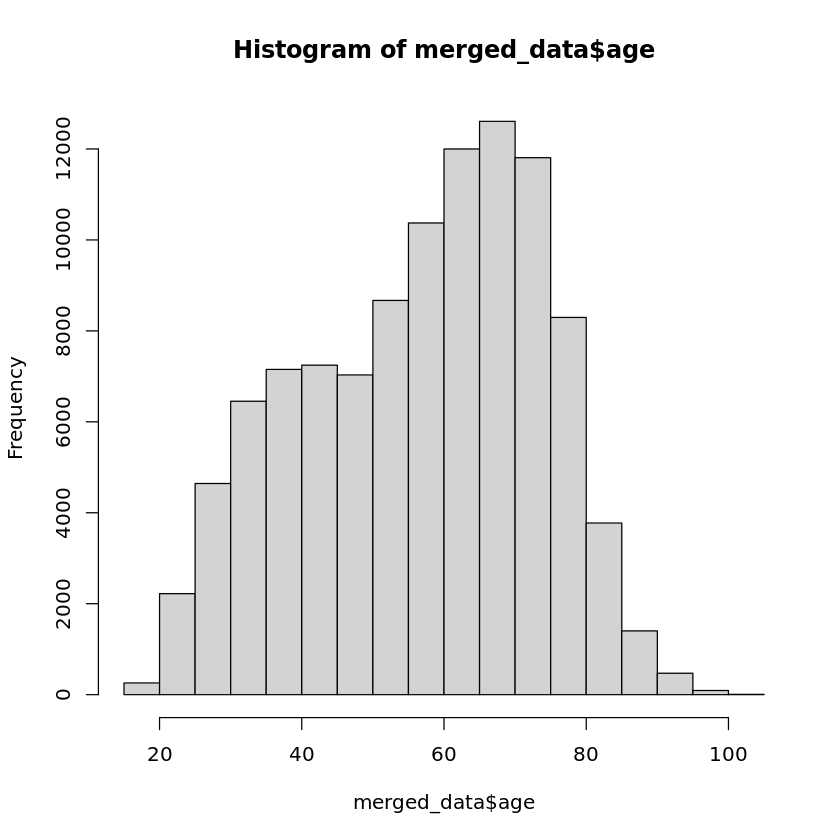

In [6]:
hist(merged_data$age)
summary(merged_data$age)

merged_data <- merged_data %>%
  mutate(age_buckets = case_when(
    age <= 35 ~ "18_35",
    age <= 50 ~ "36_50",
    age <= 64 ~ "51_64",
    TRUE      ~ "65_105"
  ))

table(merged_data$age_buckets)

# Regressions

In [7]:
generate_formulas <- function(disease) {
  covariates <- c("record_depth", "visit_frequency")
  sex_terms <- c("SexGenderCis_male", "SexGenderSGM")

  if (disease %in% c("CKD", "t1d")) {
    sex_terms <- setdiff(sex_terms, "SexGenderSGM")
  }
  if (disease == "BreastC") {
    sex_terms <- setdiff(sex_terms, "SexGenderCis_male")
  }
  if (disease == "ProstateC") {
    sex_terms <- setdiff(sex_terms, "SexGenderCis_female")
  }

  base <- paste(c(covariates, sex_terms), collapse = " + ")
  score <- paste0(disease, "_adjusted_score")
  PsRS  <- paste0(disease, "_PsRS")

  list(
    Base    = as.formula(paste(disease, "~", base)),
    Genetic = as.formula(paste(disease, "~", paste(c(base, score), collapse = " + "))),
    Social  = as.formula(paste(disease, "~", paste(c(base, PsRS),  collapse = " + ")))
  )
}


In [8]:
fit_by_age_groups <- function(formulas, disease, data) {

  data %>%
    group_by(age_buckets) %>%
    group_map(~ {

      map_dfr(
        names(formulas),
        function(model_name) {

          model <- glm(formulas[[model_name]], data = .x, family = binomial)

          preds <- predict(model, type = "response")
          actuals <- model$y

          if (length(unique(actuals)) > 1) {
            roc_obj <- roc(actuals, preds, quiet = TRUE)
            auc <- as.numeric(roc_obj$auc)
            auc_ci <- as.numeric(ci.auc(roc_obj))
          } else {
            auc <- NA
            auc_ci <- c(NA, NA, NA)
          }

          tidy(model) %>%
            mutate(
              Disease = disease,
              Model   = model_name,
              age_buckets = .y$age_buckets,
              AUC = auc,
              AUC_CI_Lower = auc_ci[1],
              AUC_CI_Upper = auc_ci[3]
            )
        }
      )
    }) %>%
    bind_rows()
}

combinations <- expand_grid(
  disease = unlist(diseases)
)

results <- combinations %>%
  rowwise() %>%
  mutate(
    formulas = list(generate_formulas(disease)),
    age_group_results = list(
      fit_by_age_groups(formulas, disease, merged_data)
    )
  ) %>%
  ungroup() %>%
  select(age_group_results) %>%
  unnest(age_group_results)

auc_results<- results |> 
        select("Disease", "Model", "age_buckets", "AUC", "AUC_CI_Lower", "AUC_CI_Upper") |>
        distinct()
     


Warning message:
“There were 6 warnings in `mutate()`.
The first warning was:
ℹ In argument: `age_group_results = list(fit_by_age_groups(formulas, disease,
  merged_data))`.
ℹ In row 1.
Caused by warning:
! glm.fit: fitted probabilities numerically 0 or 1 occurred
ℹ Run `dplyr::last_dplyr_warnings()` to see the 5 remaining warnings.”


### Check case distribution

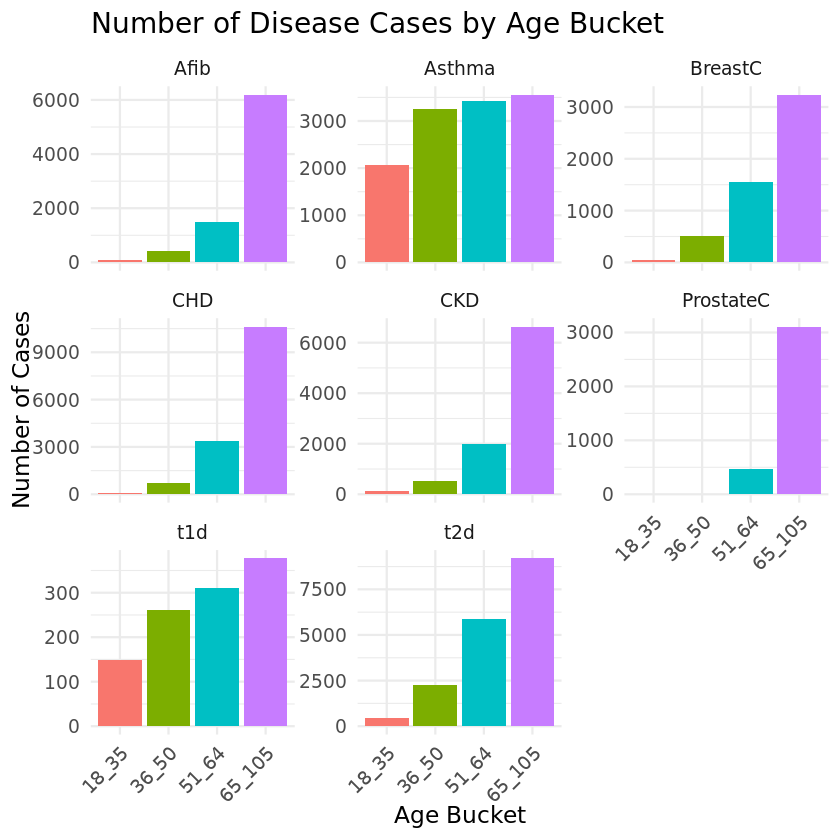

In [9]:
count_cases_by_age_buckets <- function(disease, data) {

  # validate input
  stopifnot(disease %in% names(data))
  stopifnot("age_buckets" %in% names(data))

  data %>%
    filter(!is.na(age_buckets)) %>%
    group_by(age_buckets) %>%
    summarise(
      Disease = disease,
      n_total = n(),
      n_cases = sum(.data[[disease]] == 1, na.rm = TRUE),
      n_controls = sum(.data[[disease]] == 0, na.rm = TRUE),
      case_rate = n_cases / n_total,
      .groups = "drop"
    ) %>%
    arrange(age_buckets)
}


case_count_table <- tibble(disease = diseases) %>%
  rowwise() %>%
  mutate(
    case_counts = list(count_cases_by_age_buckets(disease, merged_data))
  ) %>%
  unnest(case_counts)


ggplot(case_count_table, 
       aes(x = age_buckets, y = n_cases, fill = age_buckets)) +
  geom_col(position = "dodge") +
  facet_wrap(~ Disease, scales = "free_y") +
  labs(
    title = "Number of Disease Cases by Age Bucket",
    x = "Age Bucket",
    y = "Number of Cases",
    fill = "Age Bucket"
  ) +
  theme_minimal(base_size = 14) +
  theme(
    legend.position = "none",
    axis.text.x = element_text(angle = 45, hjust = 1)
  )


# DeLong's Test Of Significance

In [10]:
fit_by_age_groups <- function(formula_list, disease, data) {
  
  data %>%
    group_by(age_buckets) %>%
    group_map(~ {
      
      # Skip specific disease-age_bucket combinations
      if ((disease == "BreastC" && .y$age_buckets == "18_35") ||
          (disease == "ProstateC" && .y$age_buckets %in% c("18_35", "36_50"))) {
        return(tibble(
          Disease = disease,
          age_buckets = .y$age_buckets,
          Base_AUC = NA_real_,
          Genetic_AUC = NA_real_,
          Social_AUC = NA_real_,
          p_Base_vs_Genetic = NA_real_,
          p_Base_vs_Social  = NA_real_
        ))
      }
      
      # Fit models
      model_base    <- glm(formula_list$Base, data = .x, family = binomial())
      model_genetic <- glm(formula_list$Genetic, data = .x, family = binomial())
      model_social  <- glm(formula_list$Social, data = .x, family = binomial())
      
      actuals <- model_base$y
      
      # If all 0 or all 1 → return NAs
      if (length(unique(actuals)) < 2) {
        return(tibble(
          Disease = disease,
          age_buckets = .y$age_buckets,
          Base_AUC = NA_real_,
          Genetic_AUC = NA_real_,
          Social_AUC = NA_real_,
          p_Base_vs_Genetic = NA_real_,
          p_Base_vs_Social  = NA_real_
        ))
      }
      
      # Compute ROC objects
      roc_base    <- roc(actuals, predict(model_base, type="response"), quiet = TRUE)
      roc_genetic <- roc(actuals, predict(model_genetic, type="response"), quiet = TRUE)
      roc_social  <- roc(actuals, predict(model_social,  type="response"), quiet = TRUE)
      
      # DeLong comparisons
      p_gen <- roc.test(roc_base, roc_genetic, method="delong")$p.value
      p_soc <- roc.test(roc_base, roc_social,  method="delong")$p.value
      
      tibble(
        Disease = disease,
        age_buckets = .y$age_buckets,
        Base_AUC = as.numeric(roc_base$auc),
        Base_AUC_CI_Lower = ci.auc(roc_base)[1],
        Base_AUC_CI_Upper = ci.auc(roc_base)[3],
        Genetic_AUC = as.numeric(roc_genetic$auc),
        Genetic_AUC_CI_Lower = ci.auc(roc_genetic)[1],
        Genetic_AUC_CI_Upper = ci.auc(roc_genetic)[3],
        Social_AUC = as.numeric(roc_social$auc),
        Social_AUC_CI_Lower = ci.auc(roc_social)[1],
        Social_AUC_CI_Upper = ci.auc(roc_social)[3],
        p_Base_vs_Genetic = p_gen,
        p_Base_vs_Social  = p_soc
      )
      
    }, .keep = TRUE) %>%
    bind_rows()
}


results_delong <- combinations %>%
  rowwise() %>%
  mutate(
    formula_list = list(generate_formulas(disease)),
    delong_results = list(fit_by_age_groups(formula_list, disease, merged_data))
  ) %>%
  ungroup() %>%
  select(-formula_list) %>%  # drop formula_list if still present
  unnest(delong_results)

 

Warning message:
“There were 6 warnings in `mutate()`.
The first warning was:
ℹ In argument: `delong_results = list(fit_by_age_groups(formula_list, disease,
  merged_data))`.
ℹ In row 1.
Caused by warning:
! glm.fit: fitted probabilities numerically 0 or 1 occurred
ℹ Run `dplyr::last_dplyr_warnings()` to see the 5 remaining warnings.”


# Graph Percent Difference in AUC

In [11]:
library(tidyverse)
library(ggplot2)

facet_order <- c(
  "Breast\nCancer", "Prostate\nCancer", "Afib", "T2D",
  "CKD", "CHD", "Asthma", "T1D"
)

# Map names
results_delong <- results_delong  %>% mutate(Disease = as.character(Disease), 
                                                    Disease = recode(Disease, 
                                                    !!!disease_name_mapping_short, 
                                                                     .default = Disease))

# Compute percent difference relative to Base
heatmap_data <- results_delong %>%
  mutate(
    Genetic_vs_Base = (Genetic_AUC - Base_AUC) / Base_AUC * 100,
    Social_vs_Base  = (Social_AUC  - Base_AUC) / Base_AUC * 100
  ) %>%
  select(Disease, age_buckets, Base_AUC, Social_AUC, Genetic_AUC, Genetic_vs_Base, Social_vs_Base, 
         p_Base_vs_Genetic, p_Base_vs_Social) %>%
  pivot_longer(
    cols = c(Genetic_vs_Base, Social_vs_Base),
    names_to = "Model",
    values_to = "Percent_Diff"
  ) %>%
  mutate(
    Model = recode(Model,
                   Genetic_vs_Base = "Genetic",
                   Social_vs_Base = "Social"),
    # Choose appropriate p-value column for each model
    p_value = case_when(
      Model == "Genetic" ~ p_Base_vs_Genetic,
      Model == "Social"  ~ p_Base_vs_Social
    ),
    # Add significance stars
    sig_star = case_when(
      is.na(p_value) ~ "",
      p_value < (0.05 / 64) ~ "**",
      p_value < 0.05 ~ "*",
      TRUE ~ ""
    )
  )

heatmap_data <- heatmap_data  %>% mutate(Disease = factor(Disease, levels = facet_order))



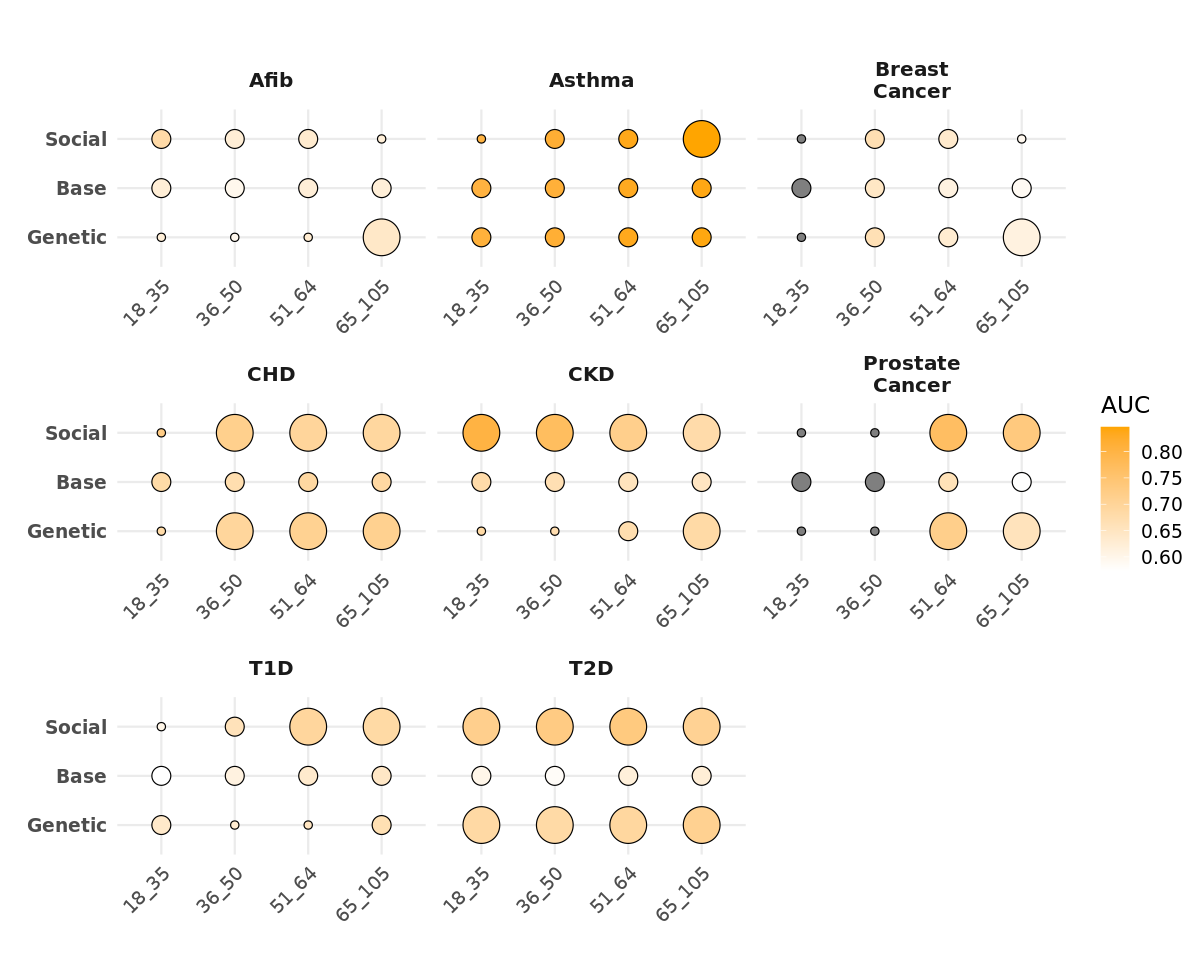

In [12]:
options(repr.plot.width = 10, repr.plot.height = 8)  # Set width and height

# Define Bonferroni threshold
alpha_bonf <- 0.05 / (2*nrow(results_delong))

heatmap_data_bubble <- results_delong %>%
  pivot_longer(
    cols = c(Base_AUC, Social_AUC, Genetic_AUC),
    names_to = "Model",
    values_to = "AUC"
  ) %>%
  mutate(
    Model = recode(Model,
                   Base_AUC    = "Base",
                   Social_AUC  = "Social",
                   Genetic_AUC = "Genetic"),
    Model = factor(Model, levels = c("Genetic", "Base", "Social")),
    bubble_size = case_when(
      Model == "Base" ~ 5,  # fixed size
      Model == "Social" & p_Base_vs_Social < alpha_bonf ~ 10,
      Model == "Social" & p_Base_vs_Social < 0.05        ~ 5,
      Model == "Social" ~ 2,
      Model == "Genetic" & p_Base_vs_Genetic < alpha_bonf ~ 10,
      Model == "Genetic" & p_Base_vs_Genetic < 0.05      ~ 5,
      Model == "Genetic" ~ 2
    )
  )

# Bubble plot
ggplot(heatmap_data_bubble, aes(x = age_buckets, y = Model)) +
  geom_point(aes(size = bubble_size, fill = AUC), shape = 21, color = "black") +
  scale_fill_gradient(
    low = "white", high = "orange",
    name = "AUC"
  ) +
  scale_size_identity() +  # sizes are fixed based on bubble_size
  facet_wrap(~Disease, ncol = 3, scales = "free_x") +
  labs(
    x = "",
    y = "",
    title = ""
  ) +
  theme_minimal(base_size = 14) +
  theme(
    axis.text.x = element_text(angle = 45, hjust = 1),
    axis.text.y = element_text(face = "bold"),
    strip.text = element_text(size = 12, face = "bold"),
    plot.title = element_text(hjust = 0.5)
  )


# Save data

In [13]:
#results$Disease <- disease_name_mapping[results$Disease]

results_with_stars <- results %>%
  left_join(results_delong, by = c("Disease", "age_buckets")) %>%
  mutate(
    bonf_thresh = 0.05 / (8*8),  # Bonferroni threshold
    sig_star = case_when(
      p_Base_vs_Genetic < bonf_thresh ~ "**",
      p_Base_vs_Genetic < 0.05 ~ "*",
      p_Base_vs_Social < bonf_thresh ~ "**",
      p_Base_vs_Social < 0.05 ~ "*",
      TRUE ~ ""  # no star for other quantiles
    )
  )



In [14]:
# Filter for terms ending with _adjusted_score or _PsRS
results_filtered <- results %>%
  filter(str_detect(term, "(_adjusted_score|_PsRS)$"))

# Summarize estimates by Disease, SDoH_Variable, and Quantile_Group
estimate_summary <- results_filtered %>%
  group_by(Disease, Model, age_buckets) %>%
  summarize(
    Estimate = mean(estimate, na.rm = TRUE),
    SE = mean(std.error, na.rm = TRUE),
    AUC = mean(AUC, na.rm = TRUE),
    .groups = "drop"
  ) %>%
  mutate(
    OR = Estimate,
    OR_Lower = Estimate - 1.96 * SE,
    OR_Upper = Estimate + 1.96 * SE
  )

head(estimate_summary)




Disease,Model,age_buckets,Estimate,SE,AUC,OR,OR_Lower,OR_Upper
<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Afib,Genetic,18_35,-1.254628,0.9308415,0.6224091,-1.254628,-3.0790776,0.5698211
Afib,Genetic,36_50,1.347464,0.4462464,0.5945553,1.347464,0.4728212,2.2221069
Afib,Genetic,51_64,1.925786,0.2577638,0.6303884,1.925786,1.4205686,2.4310027
Afib,Genetic,65_105,2.750083,0.1514497,0.6411455,2.750083,2.4532419,3.0469248
Afib,Social,18_35,5.040016,1.1515472,0.6831575,5.040016,2.7829839,7.2970488
Afib,Social,36_50,3.100138,0.5420719,0.6247986,3.100138,2.0376775,4.1625993


In [15]:
# Map names
estimate_q15 <- estimate_summary %>% mutate(Disease = as.character(Disease), 
                                                    Disease = recode(Disease, 
                                                    !!!disease_name_mapping_short, 
                                                                     .default = Disease) )

#Save table
destination_filename <- 'OR_age_stratified_analyses.csv'
write_excel_csv(estimate_q15, destination_filename)
system(paste0("gsutil cp ./", destination_filename, " ", my_bucket, "/data/"), intern=T)

character(0)